In [3]:
import sys
print("python:", sys.version.split()[0])
print("kernel:", sys.executable, "\n")

for name in ["coffea", "uproot", "awkward", "numpy", "matplotlib", "hist", "mplhep", "vector"]:
    try:
        mod = __import__(name)
        print(f"  [ok]      {name:<12s} {getattr(mod, '__version__', '?')}")
    except ImportError:
        print(f"  [MISSING] {name}")

python: 3.10.14
kernel: /depot/cms/conda_envs/bhanda25/Coffea-Santosh/bin/python 

  [ok]      coffea       2024.2.2
  [ok]      uproot       5.3.10
  [ok]      awkward      2.6.5
  [ok]      numpy        1.26.4
  [ok]      matplotlib   3.9.1
  [ok]      hist         2.7.3
  [ok]      mplhep       0.3.50
  [ok]      vector       1.4.1


In [4]:
import os
import pathlib
import time
import warnings
from concurrent.futures import ThreadPoolExecutor

# coffea 2024.2.2 warns on import that a future release will hand its four-vector
# maths to `vector`, the package you used in Lab 1 (more on that in §1.3). Nothing
# we do is affected, so we silence that one warning. Silencing warnings you have
# not read is a bad habit; this one has been read.
warnings.filterwarnings("ignore", category=FutureWarning, module="coffea.*")

import awkward as ak
import hist
import matplotlib.pyplot as plt
import mplhep as hep
import numpy as np

import coffea
from coffea import processor
from coffea.nanoevents import NanoEventsFactory, BaseSchema
from coffea.nanoevents.methods import candidate


hep.style.use("CMS")
print("coffea", coffea.__version__)

coffea 2024.2.2


In [15]:
import json
import urllib.request

RECID = 75589
with urllib.request.urlopen(f"https://opendata.cern.ch/api/records/{RECID}", timeout=60) as r:
    meta = json.load(r)["metadata"]

print("title      :", meta["title"])
print("DOI        :", meta["doi"])
print("licence    :", meta["license"])
print("distribution:", json.dumps(meta["distribution"], indent=2))
meta_files = []
for i in range(5):
    for j in range(len(meta["_file_indices"][i]['files'])):
        #print("Files:", meta["_file_indices"][i]['files'][j])
        meta_files.append(meta["_file_indices"][i]['files'][j])
print(meta_files[0:3])

title      : /ZZTo4L_TuneCP5_13TeV_powheg_pythia8/RunIISummer20UL16NanoAODv9-106X_mcRun2_asymptotic_v17-v1/NANOAODSIM
DOI        : 10.7483/OPENDATA.CMS.3Z2W.O02W
licence    : {'attribution': 'CC0-1.0'}
distribution: {
  "formats": [
    "nanoaodsim",
    "root"
  ],
  "number_events": 52104000,
  "number_files": 99,
  "size": 71479443458
}
[{'availability': 'online', 'bucket': 'db3870f1-c425-4e5e-83a3-6350604fa413', 'checksum': 'adler32:6af0d28f', 'file_id': '227c3166-3a84-4c93-b561-9e60463cc0c4', 'filename': '051E9D22-4F30-8E49-8477-644E65768282.root', 'key': 'CMS_mc_RunIISummer20UL16NanoAODv9_ZZTo4L_TuneCP5_13TeV_powheg_pythia8_NANOAODSIM_106X_mcRun2_asymptotic_v17-v1_2430000_file_index.json_0', 'size': 232295116, 'tags': {}, 'uri': 'root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ZZTo4L_TuneCP5_13TeV_powheg_pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v1/2430000/051E9D22-4F30-8E49-8477-644E65768282.root', 'version_id': '3296448b-1ed8-401b-884c-f0256bdc4ea7'

In [16]:
import pathlib
import uproot

background = []
for i in range(5):
    for j in range(len(meta["_file_indices"][i]['files'])):
        # YOUR CODE HERE
        XROOTD_URL = meta_files[i]["uri"]
        HTTPS_URL  = XROOTD_URL.replace("root://eospublic.cern.ch/", "https://eospublic.cern.ch/")
        EXPECTED   = meta_files[i]["size"]
        
        DATA_DIR = pathlib.Path(os.environ.get("CLUSTER_SCRATCH", pathlib.Path.home())) / "higgs_background_data"
        # DATA_DIR.mkdir(parents=True, exist_ok=True)
        LOCAL_FILE = DATA_DIR / meta["_file_indices"][i]["files"][j]["key"]
        
        try:
            FILE = str(LOCAL_FILE)                      # from Part 2
            assert pathlib.Path(FILE).exists()
            print("Using local file from Part 2")
        except (NameError, AssertionError):
            FILE = ("root://eospublic.cern.ch//eos/opendata/cms/derived-data/"
                    "AOD2NanoAODOutreachTool/ForHiggsTo4Leptons/ZZTo4mu.root")
            # /eos/opendata/cms/dataset-semantics/NanoAODSIM/75589/ZZTo4L_TuneCP5_13TeV_powheg_pythia8_doc.root
            print("Local file not found - streaming over XRootD (slower)")
        
        background.append(uproot.open(FILE)["Events"])

count = 0
for i in range(len(background)):
    count += background[i].num_entries
#print(f"\nnumber of events: {(events[0].num_entries)}")
print("Number of Events:", count)

Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local file from Part 2
Using local fi

In [12]:
RECID = 37728
with urllib.request.urlopen(f"https://opendata.cern.ch/api/records/{RECID}", timeout=60) as r:
    meta = json.load(r)["metadata"]

print("title      :", meta["title"])
print("DOI        :", meta["doi"])
print("licence    :", meta["license"])
print("distribution:", json.dumps(meta["distribution"], indent=2))
meta_files = []
for j in range(len(meta["_file_indices"][0]['files'])):
    #print("Files:", meta["_file_indices"][i]['files'][j])
    meta_files.append(meta["_file_indices"][0]['files'][j])
print(meta_files[0:3])

title      : /GluGluHToZZTo4L_M125_TuneCP5_13TeV_powheg2_JHUGenV7011_pythia8/RunIISummer20UL16NanoAODv9-106X_mcRun2_asymptotic_v17-v2/NANOAODSIM
DOI        : 10.7483/OPENDATA.CMS.4GPD.HQ5T
licence    : {'attribution': 'CC0-1.0'}
distribution: {
  "formats": [
    "nanoaodsim",
    "root"
  ],
  "number_events": 1000000,
  "number_files": 8,
  "size": 1696039660
}
[{'availability': 'online', 'bucket': 'b5a9ba36-e6a9-4ddb-bc0d-30f5415b0fb6', 'checksum': 'adler32:5387cdcc', 'file_id': '71753ebe-bad9-40e4-bb50-b3ed3ea9139b', 'filename': '34976A9F-8C57-044D-BB81-41704D8B017F.root', 'key': 'CMS_mc_RunIISummer20UL16NanoAODv9_GluGluHToZZTo4L_M125_TuneCP5_13TeV_powheg2_JHUGenV7011_pythia8_NANOAODSIM_106X_mcRun2_asymptotic_v17-v2_260000_file_index.json_0', 'size': 9521067, 'tags': {}, 'uri': 'root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/GluGluHToZZTo4L_M125_TuneCP5_13TeV_powheg2_JHUGenV7011_pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/260000/34976A9F-8C57-044D-BB8

In [13]:
signal = []
for j in range(len(meta["_file_indices"][0]['files'])):
    # YOUR CODE HERE
    XROOTD_URL = meta_files[0]["uri"]
    HTTPS_URL  = XROOTD_URL.replace("root://eospublic.cern.ch/", "https://eospublic.cern.ch/")
    EXPECTED   = meta_files[0]["size"]
    
    DATA_DIR = pathlib.Path(os.environ.get("CLUSTER_SCRATCH", pathlib.Path.home())) / "higgs_signal_data"
    # DATA_DIR.mkdir(parents=True, exist_ok=True)
    LOCAL_FILE = DATA_DIR / meta_files[j]["key"]
    
    try:
        FILE = str(LOCAL_FILE)                      # from Part 2
        assert pathlib.Path(FILE).exists()
        print("Using local file")
    except (NameError, AssertionError):
        FILE = ("root://eospublic.cern.ch//eos/opendata/cms/derived-data/"
                "AOD2NanoAODOutreachTool/ForHiggsTo4Leptons/ZZTo4mu.root")
        # /eos/opendata/cms/dataset-semantics/NanoAODSIM/75589/ZZTo4L_TuneCP5_13TeV_powheg_pythia8_doc.root
        print("Local file not found - streaming over XRootD (slower)")
    
    signal.append(uproot.open(FILE)["Events"])
count = 0
for i in range(len(signal)):
    count += signal[i].num_entries
#print(f"\nnumber of events: {(events[0].num_entries)}")
print("Number of Events:", count)
print(signal[0])

Using local file
Using local file
Using local file
Using local file
Using local file
Using local file
Using local file
Using local file
Number of Events: 1000000
<TTree 'Events' (1504 branches) at 0x150e7c176710>


In [17]:
import vector
vector.register_awkward()

events = [background, signal]
M_Z = 91.1876

BRANCHES = ["Muon_pt", "Muon_eta", "Muon_phi", "Muon_mass", "Muon_charge",
            "Muon_pfRelIso04_all", "Muon_dxy", "Muon_dxyErr", "Muon_dz", "Muon_dzErr"]

def features_from_chunk(raw):
    muons = ak.zip({
        "pt": raw.Muon_pt, "eta": raw.Muon_eta, "phi": raw.Muon_phi, "mass": raw.Muon_mass,
        "charge": raw.Muon_charge, "iso": raw.Muon_pfRelIso04_all,
        "dxy_sig": abs(raw.Muon_dxy / raw.Muon_dxyErr),
        "dz_sig":  abs(raw.Muon_dz  / raw.Muon_dzErr),
    }, with_name="Momentum4D")

    # --- Lab 1 selection ---
    muons = muons[(muons.pt > 5) & (abs(muons.eta) < 2.4) & (muons.iso < 0.40)
                  & (muons.dxy_sig < 4) & (muons.dz_sig < 4)]
    ev = muons[ak.num(muons) == 4]
    ev = ev[ak.sum(ev.charge, axis=1) == 0]
    ev = ev[ak.argsort(ev.pt, ascending=False)]

    if len(ev) == 0:                      # nothing left after 4-muon, charge-sum cut
        return None

    # --- thresholds on the two hardest muons ---
    ev = ev[(ev[:, 0].pt > 20) & (ev[:, 1].pt > 10)]

    if len(ev) == 0:                      # nothing left after pT thresholds
        return None

    # --- pair the muons into two Z candidates ---
    idx   = ak.local_index(ev)
    pairs = ak.argcombinations(ev, 2, fields=["i", "j"])
    os_p  = pairs[(ev.charge[pairs.i] + ev.charge[pairs.j]) == 0]

    zcand = ev[os_p.i] + ev[os_p.j]
    best  = ak.argmin(abs(zcand.mass - M_Z), axis=1, keepdims=True)

    i1, j1 = ak.flatten(os_p.i[best]), ak.flatten(os_p.j[best])
    Z1     = ak.flatten(zcand[best])
    dR_Z1  = ak.flatten(ev[os_p.i].deltaR(ev[os_p.j])[best])

    rest = ev[(idx != i1) & (idx != j1)]
    assert ak.all(ak.num(rest) == 2), "leftover muons must be exactly 2"
    Z2 = rest[:, 0] + rest[:, 1]

    four = ev[:, 0] + ev[:, 1] + ev[:, 2] + ev[:, 3]

    A = (Z1.mass-Z2.mass)/(Z1.mass+Z2.mass)
    feats = {
        "m4mu":      four.mass,
        "pt4mu":     four.pt,
        "absEta4mu": abs(four.eta),
        "mZ1":       Z1.mass,
        "mZ2":       Z2.mass,
        "ptZ1":      Z1.pt,
        "ptZ2":      Z2.pt,
        "dR_Z1":     dR_Z1,
        "dR_Z2":     rest[:, 0].deltaR(rest[:, 1]),
        "dR_Z1Z2":   Z1.deltaR(Z2),
        "pt1":       ev[:, 0].pt,
        "pt2":       ev[:, 1].pt,
        "pt3":       ev[:, 2].pt,
        "pt4":       ev[:, 3].pt,
        "massAsym":  A
    }
    return {k: ak.to_numpy(v).astype(np.float32) for k, v in feats.items()}
    
FEATURE_NAMES = ["m4mu", "pt4mu", "absEta4mu", "mZ1", "mZ2", "ptZ1", "ptZ2",
                 "dR_Z1", "dR_Z2", "dR_Z1Z2", "pt1", "pt2", "pt3", "pt4","massAsym"]

def build_features(tree_list, step_size="200 MB", max_chunks=None):
    out = {k: [] for k in FEATURE_NAMES}
    for tree in tree_list:
        for n, raw in enumerate(tree.iterate(BRANCHES, step_size=step_size, library="ak")):
            if max_chunks is not None and n >= max_chunks:
                break
            feats = features_from_chunk(raw)
            if feats is not None:
                for k in FEATURE_NAMES:
                    out[k].append(feats[k])
    return {k: np.concatenate(v) for k, v in out.items()}
    
data = {"signal": build_features(signal),
        "background": build_features(background)}

signal     events passing selection:  47,225
background events passing selection: 630,400
signal fraction: 7.0%   <- imbalanced, we deal with this in Part 2


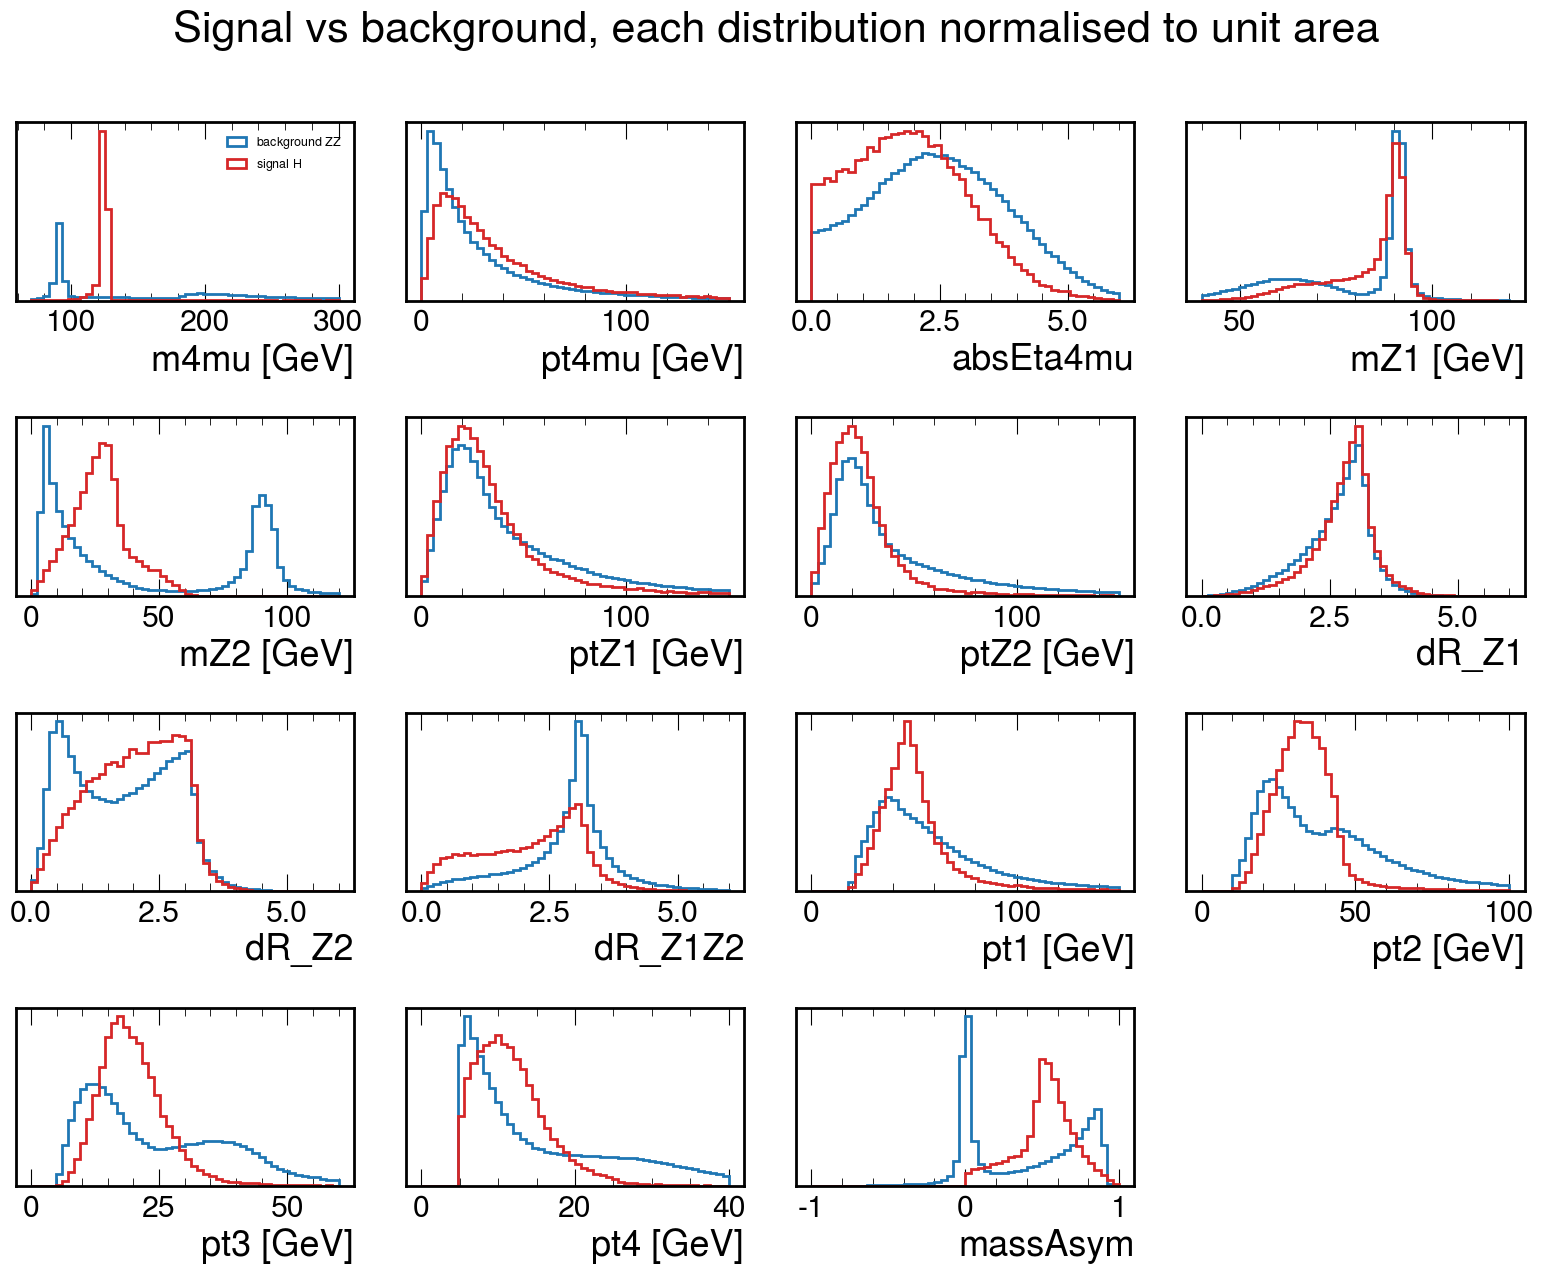

In [18]:
n_sig = len(data["signal"]["m4mu"])
n_bkg = len(data["background"]["m4mu"])
print(f"signal     events passing selection: {n_sig:>7,}")
print(f"background events passing selection: {n_bkg:>7,}")
print(f"signal fraction: {100*n_sig/(n_sig+n_bkg):.1f}%   <- imbalanced, we deal with this in Part 2")

RANGES = {"m4mu": (70, 300), "pt4mu": (0, 150), "absEta4mu": (0, 6), "mZ1": (40, 120),
          "mZ2": (0, 120), "ptZ1": (0, 150), "ptZ2": (0, 150), "dR_Z1": (0, 6),
          "dR_Z2": (0, 6), "dR_Z1Z2": (0, 6), "pt1": (0, 150), "pt2": (0, 100),
          "pt3": (0, 60), "pt4": (0, 40), "massAsym": (-1,1)}

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, name in zip(axes.flat, FEATURE_NAMES):
    lo, hi = RANGES[name]
    bins = np.linspace(lo, hi, 51)                       # 50 bins
    ax.hist(data["background"][name], bins=bins, histtype="step", lw=2,
            density=True, label="background $ZZ$", color="tab:blue")
    ax.hist(data["signal"][name], bins=bins, histtype="step", lw=2,
            density=True, label="signal $H$", color="tab:red")
    ax.set_xlabel(name + ("" if name.startswith(("dR", "abs", "massAsym")) else " [GeV]"))
    ax.set_yticks([])
for ax in axes.flat[len(FEATURE_NAMES):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=9)
fig.suptitle("Signal vs background, each distribution normalised to unit area", y=0.995)
plt.tight_layout(); plt.show()

Signal
OG: 47225
Cut: 44474
% Kept: 94.17%

Background
OG: 630400
Cut: 29539
% Kept: 4.69%
Mean: 184.53
Std dev: 130.91


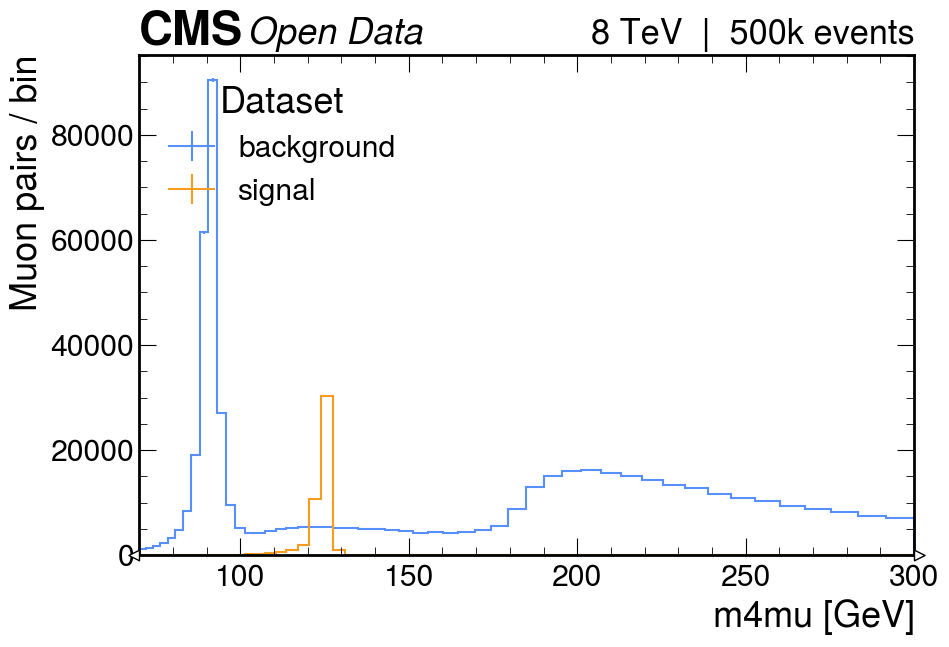

In [20]:
#Mass cut:
sig_mass_range = (data["signal"]["m4mu"] > 115) & (data["signal"]["m4mu"] < 135)

sig_array = ak.Array(data["signal"]["m4mu"])
before = len(data["signal"]["m4mu"])
after = len(sig_array[sig_mass_range])

print("Signal")
print("OG:", before)
print("Cut:", after)
print(f"% Kept: {100*after/before:.2f}%")
print()


bkg_mass_range = (data["background"]["m4mu"] > 115) & (data["background"]["m4mu"] < 135)

bkg_array = ak.Array(data["background"]["m4mu"])
before = len(data["background"]["m4mu"])
after = len(bkg_array[bkg_mass_range])

print("Background")
print("OG:", before)
print("Cut:", after)
print(f"% Kept: {100*after/before:.2f}%")
print("Mean:", f"{ak.mean(bkg_array):.2f}")
print("Std dev:", f"{ak.std(bkg_array):.2f}")

h_mass = (
    hist.Hist.new
    .StrCat(["background", "signal"], name="data", label="m4mu")
    .Log(51, 70.0, 300.0, name="mass", label=r"$m4mu$ [GeV]")
    .Int64()
)

h_mass.fill(data="background", mass=bkg_array)
h_mass.fill(data="signal", mass=sig_array)

fig, ax = plt.subplots(figsize=(10, 6.5))
h_mass.plot1d(ax=ax, overlay="data")
# ax.set_xscale("log")
# ax.set_yscale("log")
ax.set_xlim(70, 300)
ax.set_ylabel("Muon pairs / bin")
ax.legend(title="Dataset", loc="upper left")
hep.cms.label("Open Data", data=True, ax=ax, loc=0, rlabel="8 TeV  |  500k events")
plt.show()

signal     events in window:  44,474
background events in window:  29,539
signal fraction in window: 60.1%


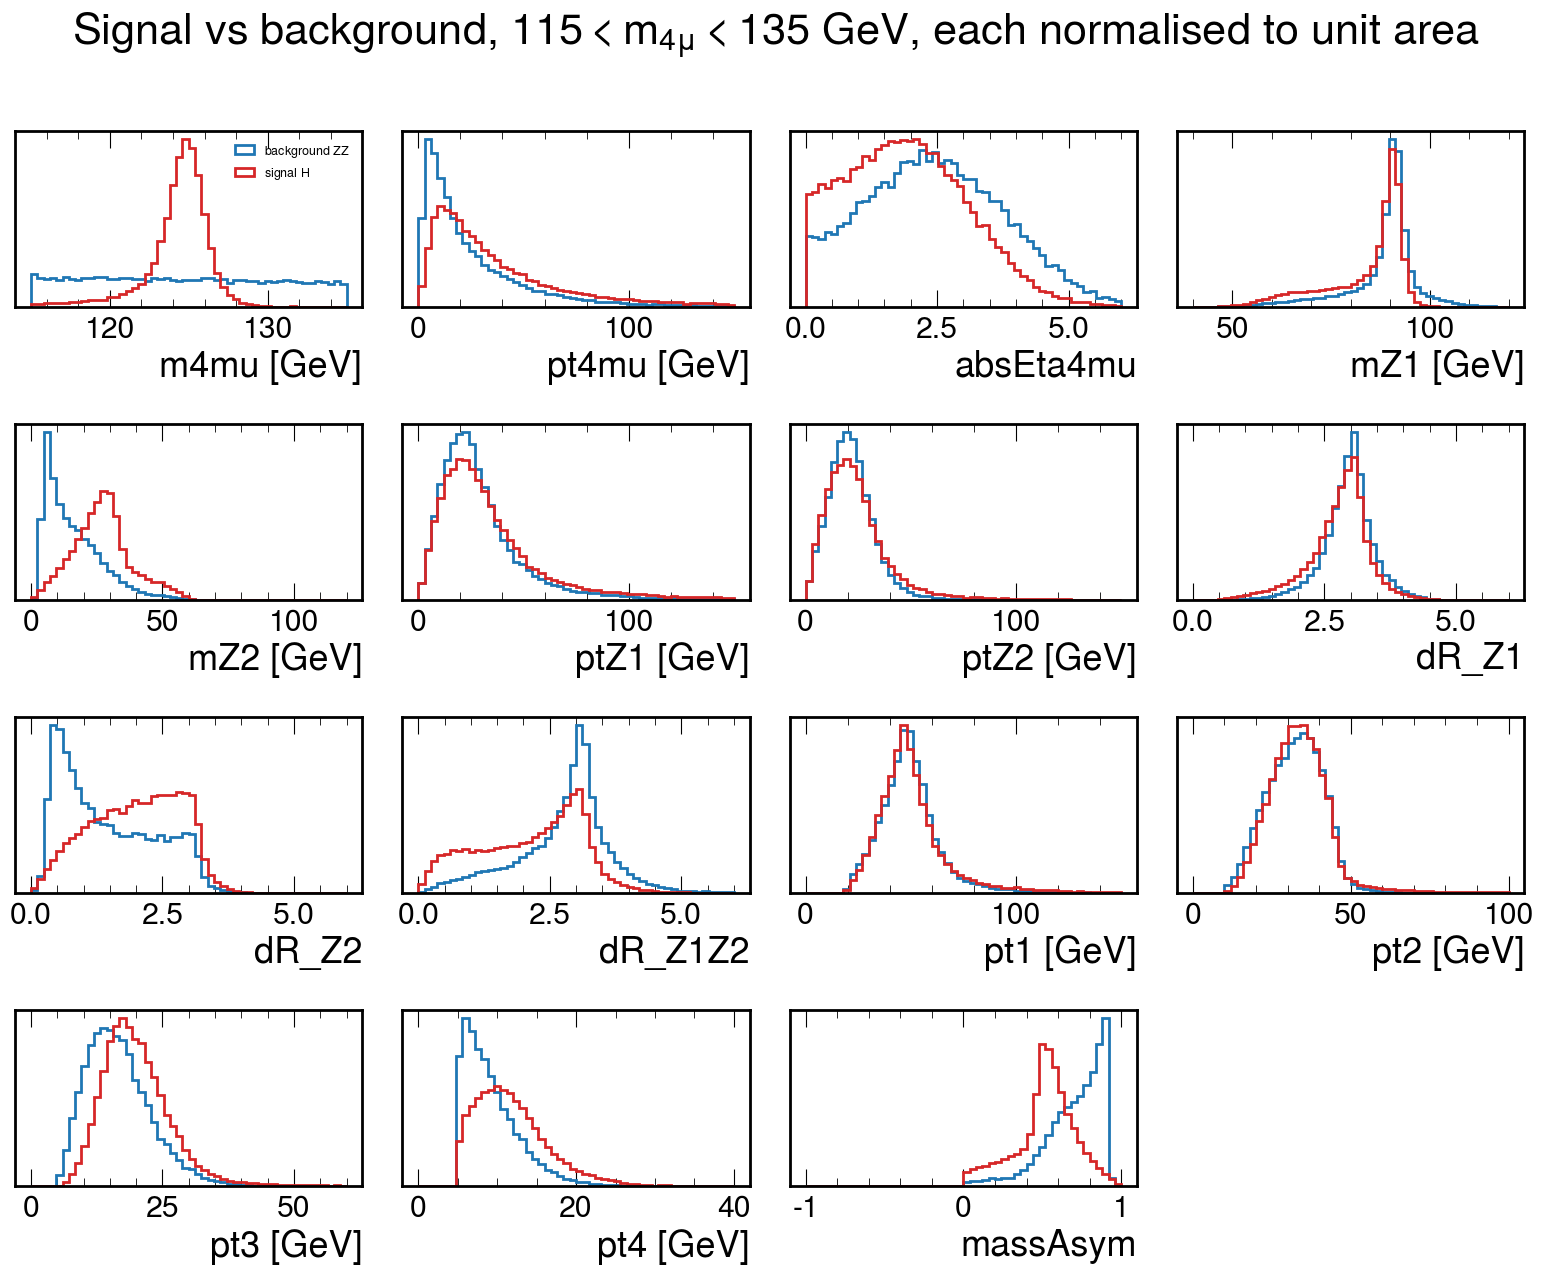

In [26]:
from sklearn.metrics import roc_auc_score

LO, HI = 115, 135
win = {cls: (np.asarray(data[cls]["m4mu"]) > LO) & (np.asarray(data[cls]["m4mu"]) < HI)
       for cls in ("signal", "background")}

n_sig_w = win["signal"].sum()
n_bkg_w = win["background"].sum()
print(f"signal     events in window: {n_sig_w:>7,}")
print(f"background events in window: {n_bkg_w:>7,}")
print(f"signal fraction in window: {100*n_sig_w/(n_sig_w+n_bkg_w):.1f}%")

RANGES_W = {**RANGES, "m4mu": (LO, HI)}

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, name in zip(axes.flat, FEATURE_NAMES):
    lo, hi = RANGES_W[name]
    bins = np.linspace(lo, hi, 51)
    ax.hist(np.asarray(data["background"][name])[win["background"]], bins=bins,
            histtype="step", lw=2, density=True, label="background $ZZ$", color="tab:blue")
    ax.hist(np.asarray(data["signal"][name])[win["signal"]], bins=bins,
            histtype="step", lw=2, density=True, label="signal $H$", color="tab:red")
    ax.set_xlabel(name + ("" if name.startswith(("dR", "abs", "massAsym")) else " [GeV]"))
    ax.set_yticks([])
for ax in axes.flat[len(FEATURE_NAMES):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=9)
fig.suptitle(f"Signal vs background, ${LO} < m_{{4\\mu}} < {HI}$ GeV, each normalised to unit area", y=0.995)
plt.tight_layout(); plt.show()

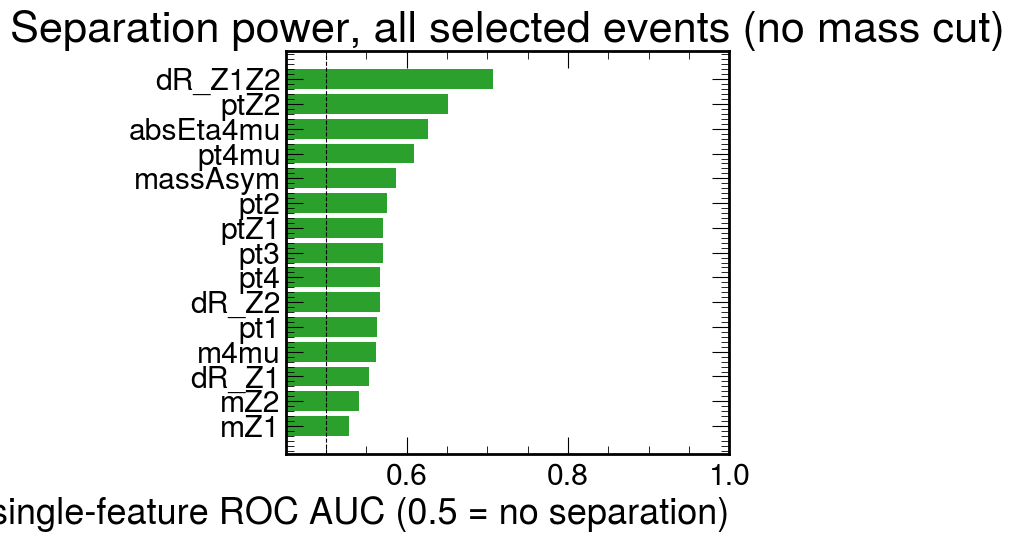

In [31]:
# --- single-feature separation power, pre-cut (all selected events) ---
aucs_pre = {}
for name in FEATURE_NAMES:
    s = np.asarray(data["signal"][name])
    b = np.asarray(data["background"][name])
    y = np.r_[np.ones(len(s)), np.zeros(len(b))]
    auc = roc_auc_score(y, np.r_[s, b])
    aucs_pre[name] = max(auc, 1 - auc)     

order = sorted(aucs_pre, key=aucs_pre.get)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(order, [aucs_pre[n] for n in order], color="tab:green")
ax.axvline(0.5, color="k", ls="--", lw=0.8)
ax.set_xlim(0.45, 1.0)
ax.set_xlabel("single-feature ROC AUC (0.5 = no separation)")
ax.set_title("Separation power, all selected events (no mass cut)")
plt.tight_layout(); plt.show()

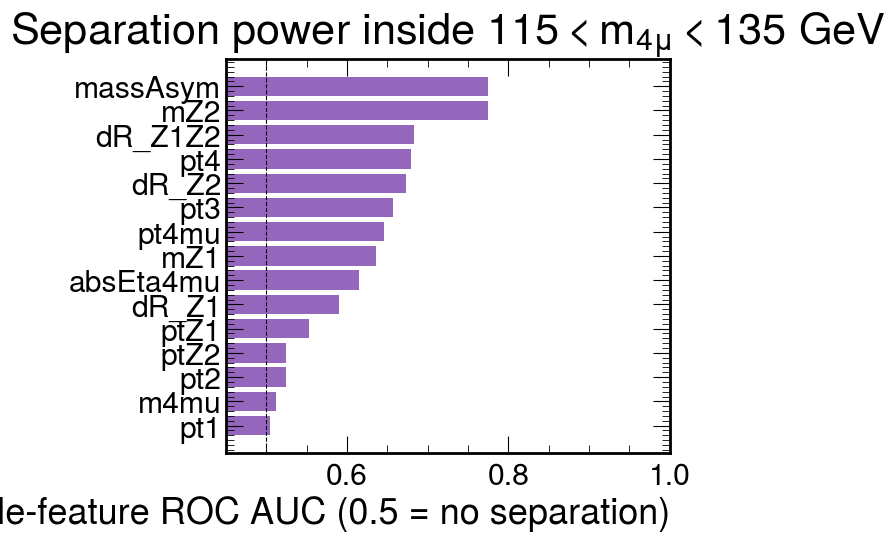

In [30]:
# --- single-feature separation power inside the window ---
aucs = {}
for name in FEATURE_NAMES:
    s = np.asarray(data["signal"][name])[win["signal"]]
    b = np.asarray(data["background"][name])[win["background"]]
    y = np.r_[np.ones(len(s)), np.zeros(len(b))]
    auc = roc_auc_score(y, np.r_[s, b])
    aucs[name] = max(auc, 1 - auc)          
order = sorted(aucs, key=aucs.get)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(order, [aucs[n] for n in order], color="tab:purple")
ax.axvline(0.5, color="k", ls="--", lw=0.8)
ax.set_xlim(0.45, 1.0)
ax.set_xlabel("single-feature ROC AUC (0.5 = no separation)")
ax.set_title(f"Separation power inside ${LO} < m_{{4\\mu}} < {HI}$ GeV")
plt.tight_layout(); plt.show()

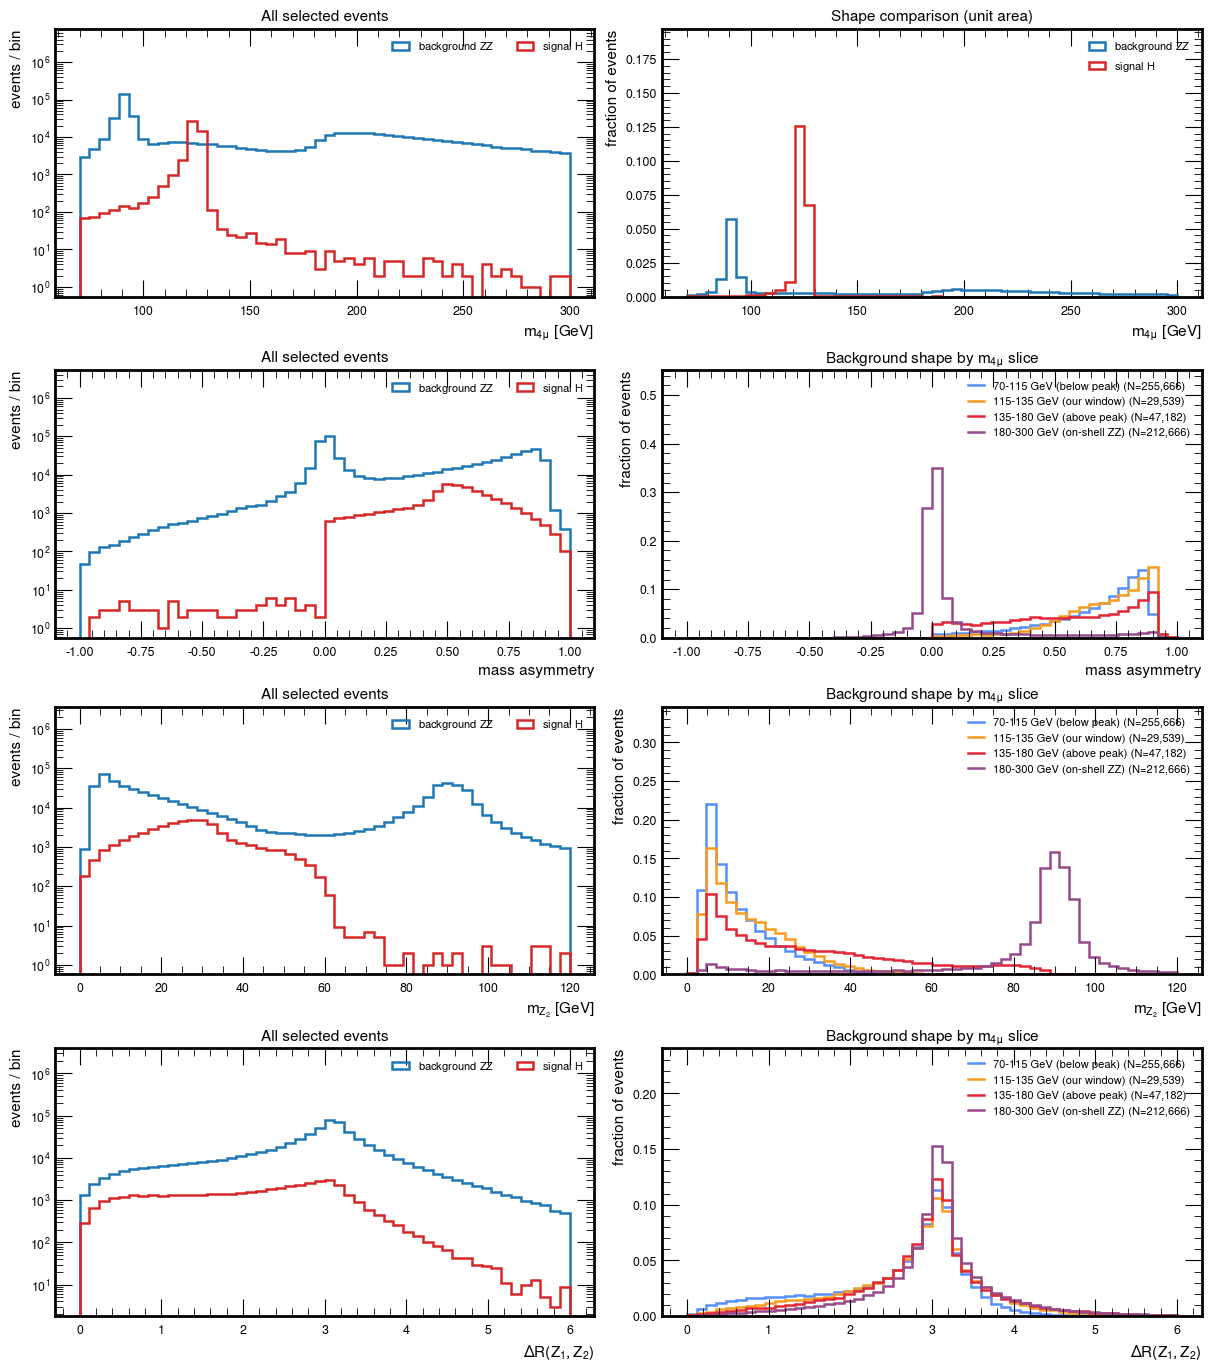

In [34]:
FEATS = ["m4mu", "massAsym", "mZ2", "dR_Z1Z2"]

XLABELS = {"m4mu": r"$m_{4\mu}$ [GeV]",
           "massAsym": "mass asymmetry",
           "mZ2": r"$m_{Z_2}$ [GeV]",
           "dR_Z1Z2": r"$\Delta R(Z_1, Z_2)$"}

slices = [("70-115 GeV (below peak)",   70, 115),
          ("115-135 GeV (our window)",  115, 135),
          ("135-180 GeV (above peak)",  135, 180),
          ("180-300 GeV (on-shell ZZ)", 180, 300)]

style = {"font.size": 10, "axes.labelsize": 11, "axes.titlesize": 11,
         "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 8}

bkg_m = np.asarray(data["background"]["m4mu"])

with plt.rc_context(style):
    fig, axes = plt.subplots(len(FEATS), 2, figsize=(12, 3.4 * len(FEATS)),
                             constrained_layout=True)

    for row, FEAT in zip(axes, FEATS):
        lo, hi = RANGES[FEAT]
        bins = np.linspace(lo, hi, 51)
        bkg_f = np.asarray(data["background"][FEAT])
        sig_f = np.asarray(data["signal"][FEAT])
        xlab = XLABELS[FEAT]

        # left: raw counts, log y
        ax = row[0]
        ax.hist(bkg_f, bins=bins, histtype="step", lw=1.8, color="tab:blue", label=r"background $ZZ$")
        ax.hist(sig_f, bins=bins, histtype="step", lw=1.8, color="tab:red",  label=r"signal $H$")
        ax.set_yscale("log")
        ax.set_ylim(top=ax.get_ylim()[1] * 30)           # headroom for the legend
        ax.set_xlabel(xlab)
        ax.set_ylabel("events / bin")
        ax.set_title("All selected events")
        ax.legend(loc="upper right", ncol=2, frameon=False)

        # right
        ax = row[1]
        if FEAT == "m4mu":
            ax.hist(bkg_f, bins=bins, histtype="step", lw=1.8, density=True,
                    color="tab:blue", label=r"background $ZZ$")
            ax.hist(sig_f, bins=bins, histtype="step", lw=1.8, density=True,
                    color="tab:red", label=r"signal $H$")
            ax.set_ylabel("fraction of events")
            ax.set_title("Shape comparison (unit area)")
        else:
            for label, a, b in slices:
                m = (bkg_m > a) & (bkg_m < b)
                vals, edges = np.histogram(bkg_f[m], bins=bins)
                if vals.sum() == 0:
                    continue
                ax.stairs(vals / vals.sum(), edges, lw=1.8, label=f"{label} (N={m.sum():,})")
            ax.set_ylabel("fraction of events")
            ax.set_title(r"Background shape by $m_{4\mu}$ slice")
        ax.set_ylim(top=ax.get_ylim()[1] * 1.5)          # headroom for the legend
        ax.set_xlabel(xlab)
        ax.legend(loc="upper right", frameon=False)

    plt.show()

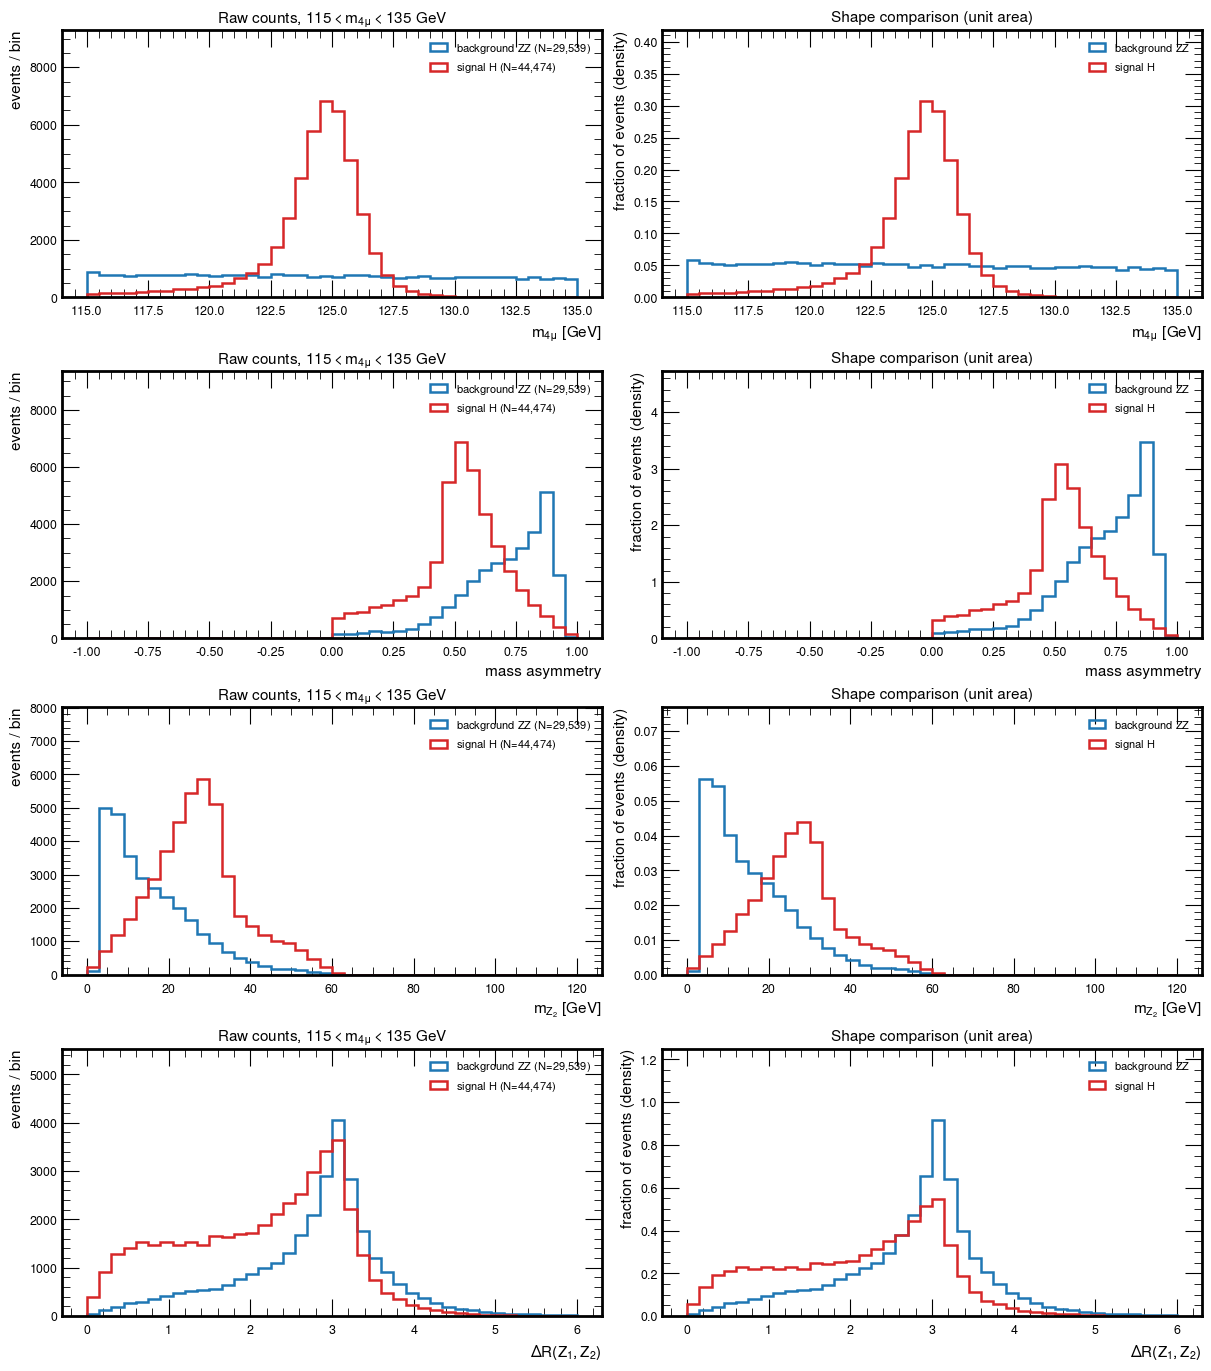

In [35]:
FEATS = ["m4mu", "massAsym", "mZ2", "dR_Z1Z2"]

XLABELS = {"m4mu": r"$m_{4\mu}$ [GeV]",
           "massAsym": "mass asymmetry",
           "mZ2": r"$m_{Z_2}$ [GeV]",
           "dR_Z1Z2": r"$\Delta R(Z_1, Z_2)$"}

LO, HI = 115, 135
RANGES_W = {**RANGES, "m4mu": (LO, HI)}      # m4mu only spans the window now

style = {"font.size": 10, "axes.labelsize": 11, "axes.titlesize": 11,
         "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 8}

# masks: True for events inside the mass window
bkg_win = (np.asarray(data["background"]["m4mu"]) > LO) & (np.asarray(data["background"]["m4mu"]) < HI)
sig_win = (np.asarray(data["signal"]["m4mu"])     > LO) & (np.asarray(data["signal"]["m4mu"])     < HI)

with plt.rc_context(style):
    fig, axes = plt.subplots(len(FEATS), 2, figsize=(12, 3.4 * len(FEATS)),
                             constrained_layout=True)

    for row, FEAT in zip(axes, FEATS):
        lo, hi = RANGES_W[FEAT]
        bins = np.linspace(lo, hi, 41)
        bkg_f = np.asarray(data["background"][FEAT])[bkg_win]
        sig_f = np.asarray(data["signal"][FEAT])[sig_win]
        xlab = XLABELS[FEAT]

        # left: raw counts
        ax = row[0]
        ax.hist(bkg_f, bins=bins, histtype="step", lw=1.8, color="tab:blue",
                label=rf"background $ZZ$ (N={len(bkg_f):,})")
        ax.hist(sig_f, bins=bins, histtype="step", lw=1.8, color="tab:red",
                label=rf"signal $H$ (N={len(sig_f):,})")
        ax.set_ylim(0, ax.get_ylim()[1] * 1.3)           # headroom for the legend
        ax.set_xlabel(xlab)
        ax.set_ylabel("events / bin")
        ax.set_title(rf"Raw counts, ${LO} < m_{{4\mu}} < {HI}$ GeV")
        ax.legend(loc="upper right", frameon=False)

        # right: shapes only (each class normalised to unit area)
        ax = row[1]
        ax.hist(bkg_f, bins=bins, histtype="step", lw=1.8, density=True,
                color="tab:blue", label=r"background $ZZ$")
        ax.hist(sig_f, bins=bins, histtype="step", lw=1.8, density=True,
                color="tab:red", label=r"signal $H$")
        ax.set_ylim(0, ax.get_ylim()[1] * 1.3)
        ax.set_xlabel(xlab)
        ax.set_ylabel("fraction of events (density)")
        ax.set_title("Shape comparison (unit area)")
        ax.legend(loc="upper right", frameon=False)

    plt.show()

Signal
OG: 47225
Cut: 40322
% Kept: 85.38%

Background
OG: 630400
Cut: 442195
% Kept: 70.15%
Mean: 215.68
Std dev: 141.27


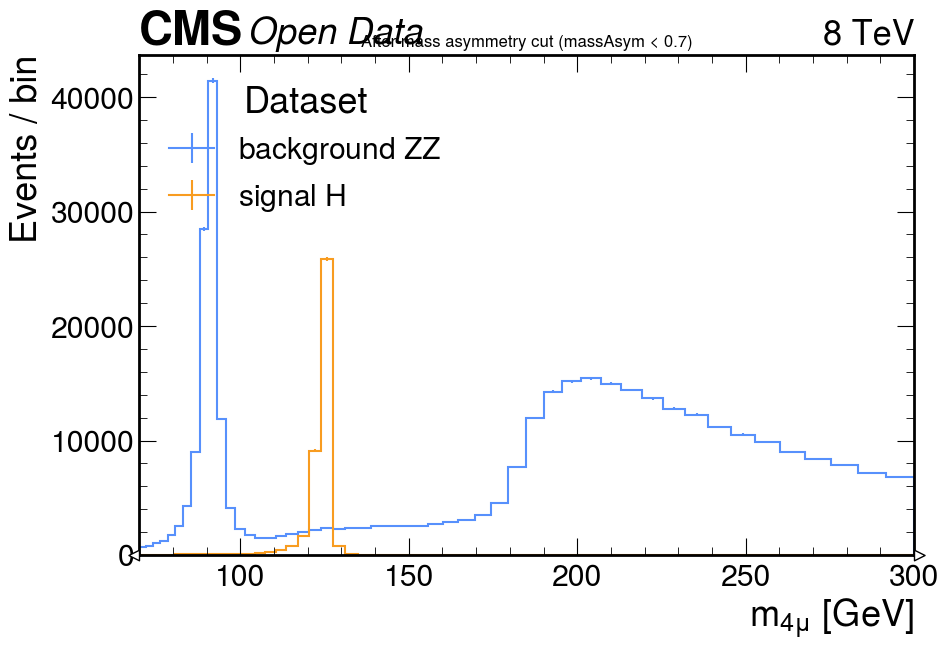

In [43]:
# massAsym cut:
ASYM_MAX = 0.7

sig_asym_mask = np.asarray(data["signal"]["massAsym"]) < ASYM_MAX
sig_array = ak.Array(data["signal"]["m4mu"])
before = len(data["signal"]["m4mu"])
after = len(sig_array[sig_asym_mask])

print("Signal")
print("OG:", before)
print("Cut:", after)
print(f"% Kept: {100*after/before:.2f}%")
print()

bkg_asym_mask = np.asarray(data["background"]["massAsym"]) < ASYM_MAX
bkg_array = ak.Array(data["background"]["m4mu"])
before = len(data["background"]["m4mu"])
after = len(bkg_array[bkg_asym_mask])

print("Background")
print("OG:", before)
print("Cut:", after)
print(f"% Kept: {100*after/before:.2f}%")
print("Mean:", f"{ak.mean(bkg_array[bkg_asym_mask]):.2f}")
print("Std dev:", f"{ak.std(bkg_array[bkg_asym_mask]):.2f}")

h_mass = (
    hist.Hist.new
    .StrCat([r"background $ZZ$", r"signal $H$"], name="dataset", label="Dataset")
    .Log(51, 70.0, 300.0, name="mass", label=r"$m_{4\mu}$ [GeV]")
    .Int64()
)

h_mass.fill(dataset=r"background $ZZ$", mass=bkg_array[bkg_asym_mask])
h_mass.fill(dataset=r"signal $H$",      mass=sig_array[sig_asym_mask])

fig, ax = plt.subplots(figsize=(10, 6.5))
h_mass.plot1d(ax=ax, overlay="dataset")
ax.set_xlim(70, 300)
ax.set_xlabel(r"$m_{4\mu}$ [GeV]")
ax.set_ylabel("Events / bin")
ax.set_title(f"After mass asymmetry cut (massAsym < {ASYM_MAX})", fontsize=12)
ax.legend(title="Dataset", loc="upper left")
hep.cms.label("Open Data", data=True, ax=ax, loc=0, rlabel="8 TeV")
plt.show()